# weight initialization: 
- forward propagation er agei amora weight initialize kori, oikhan thkek start kori

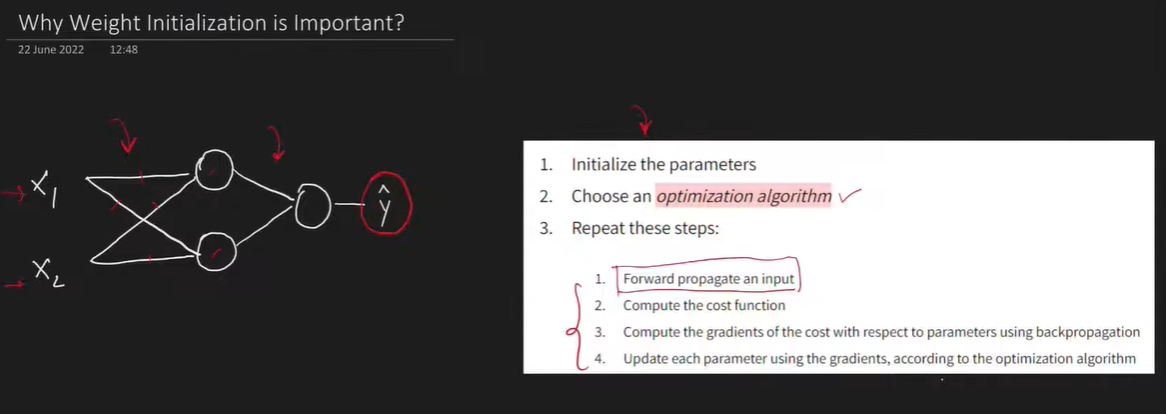

# Note: sob kisur age amora weight initialize kori, akon weight initialize perfect na hole onk dhoroner problem dekha dey
1. Vanishing gradient problem
2. Exploding gradient problem
3. slow convergence: sotik ans er kase powchaite onk late hobe

# What not to do?

# 1. case1: Zero initialize
- jodi weight= 0 dei tahole backpropagation e gradient er man er 0 hobe . ete weight er kono upgrade hobe na. orthat kono training hobe na

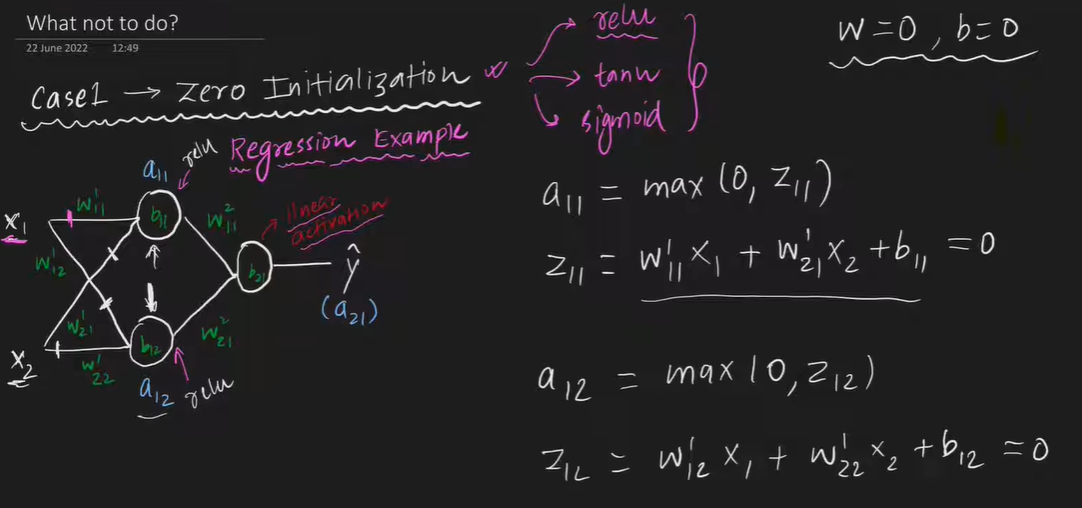

Note: sigmoid er khetre weight update holeo, eita akta signle perceptron model er moto kaj korbe. linear line draw korbe, complex pattern catch korte parbe na

# case2: Non-zero(constant value initialize)
- ei khetreo ak particular input theke ber howa sob weight er derivative sob same hobe . hidden layer onk gulo nueron add korleo seita single nueron hisebe kaj korbe ager motoi

Note: na zero set korte parbo na constant value set korte parbo. right way hocche random  value initialize kora

# case3: Random value initialize 

random value initialize korlei eita jodi onk choto hoy, and ta tanh and simoid er moto activation function use kori taholeo vanishing gradient er moto problem dekha dibe. but relu use korle vanishing gradient er moto problem face na korlei eita convergence onk slow. 

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

In [78]:
df = pd.read_csv("files/ushape.csv")

In [79]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


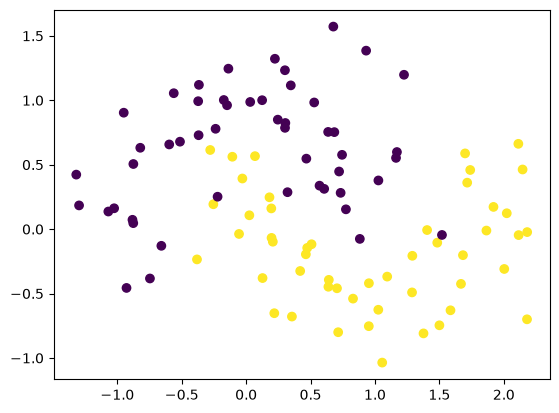

In [80]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [81]:
X = df.drop("class",axis=1)
y = df["class"]

In [82]:
model = Sequential()

model.add(Input(shape=(2,)))
model.add(Dense(2,activation='tanh'))
model.add(Dense(2,activation='tanh'))
model.add(Dense(2,activation='tanh'))
model.add(Dense(2,activation='tanh'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_39 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27 (108.00 B)

 Trainable params: 27 (108.00 B)

 Non-trainable params: 0 (0.00 B)

In [83]:
model.get_weights()

[array([[ 0.74427736,  0.6200652 ],
        [-0.61764395,  0.3662461 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.6026938 ,  0.19112611],
        [-0.81450033, -0.7920488 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.23852968, -0.18177176],
        [ 1.2004024 ,  1.0148283 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.28462481,  0.912871  ],
        [ 0.22779834, -0.6379145 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-1.0092198],
        [ 1.2491626]], dtype=float32),
 array([0.], dtype=float32)]

In [84]:
init_weight = model.get_weights()

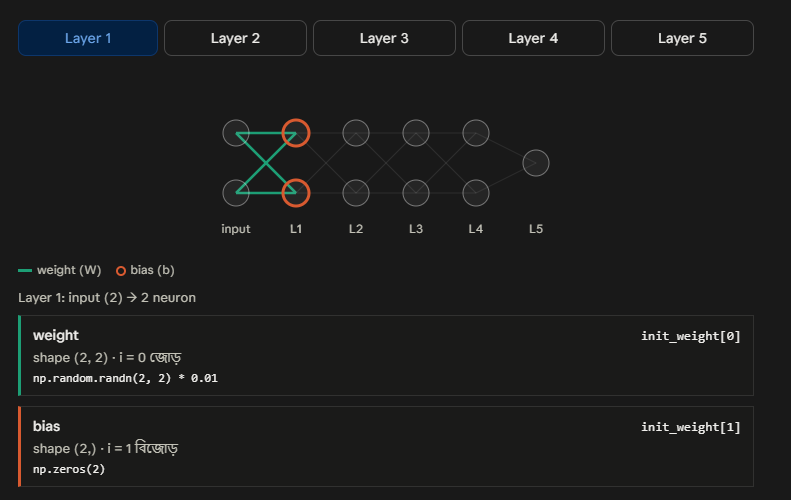

In [85]:
init_weight[0] = np.random.randn(model.get_weights()[0].shape[0], model.get_weights()[0].shape[1])*0.01
init_weight[1] = np.zeros(model.get_weights()[1].shape)
init_weight[2] = np.random.randn(model.get_weights()[2].shape[0], model.get_weights()[2].shape[1])*0.01
init_weight[3] = np.zeros(model.get_weights()[3].shape)
init_weight[4] = np.random.randn(model.get_weights()[4].shape[0], model.get_weights()[4].shape[1])*0.01
init_weight[5] = np.zeros(model.get_weights()[5].shape)
init_weight[6] = np.random.randn(model.get_weights()[6].shape[0], model.get_weights()[6].shape[1])*0.01
init_weight[7] = np.zeros(model.get_weights()[7].shape)
init_weight[8] = np.random.randn(model.get_weights()[8].shape[0], model.get_weights()[8].shape[1])*0.01
init_weight[9] = np.zeros(model.get_weights()[9].shape)

In [86]:
model.set_weights(init_weight)

In [87]:
model.get_weights()

[array([[ 0.00476407, -0.01563224],
        [-0.01140975,  0.0070638 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.00964916,  0.00569902],
        [ 0.00956092, -0.00436252]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.01595566,  0.00663764],
        [-0.0087458 ,  0.01012582]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.01063824, -0.01192303],
        [-0.01315697,  0.00849079]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.00434428],
        [-0.00249244]], dtype=float32),
 array([0.], dtype=float32)]

In [88]:
model.compile(loss="binary_crossentropy",optimizer="adam", metrics=["accuracy"])

In [89]:
history = model.fit(X,y, epochs=100, validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.4000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss

In [90]:
model.get_weights()

[array([[ 0.00485437, -0.01559892],
        [-0.01150007,  0.00703053]], dtype=float32),
 array([-1.0364470e-06, -4.6112444e-07], dtype=float32),
 array([[ 0.00974723,  0.00578922],
        [ 0.00942384, -0.00448835]], dtype=float32),
 array([-6.6179666e-05, -4.6816553e-05], dtype=float32),
 array([[-0.01594058,  0.00661585],
        [-0.00879046,  0.01018993]], dtype=float32),
 array([ 7.2994543e-04, -5.6879802e-05], dtype=float32),
 array([[-0.01046012, -0.01113302],
        [-0.01151851,  0.00698968]], dtype=float32),
 array([-5.4611355e-06,  1.0867118e-05], dtype=float32),
 array([[ 8.8815301e-05],
        [-2.2639506e-06]], dtype=float32),
 array([0.00335009], dtype=float32)]

<Axes: >

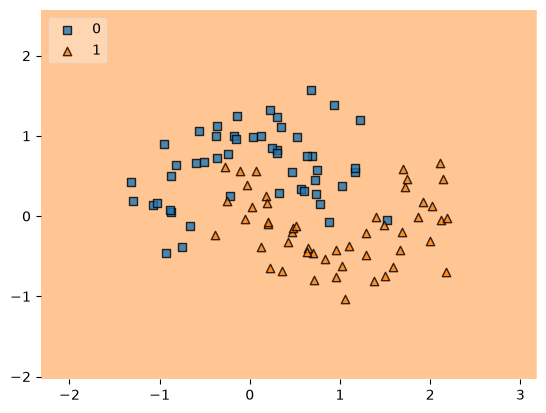

In [93]:
from mlxtend.plotting import plot_decision_regions

class KerasWrapper:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        probs = self.model.predict(X, verbose=0)
        return (probs > 0.5).astype(int).ravel()

plot_decision_regions(X.values, y.values.astype("int"),
                      clf=KerasWrapper(model), legend=2)

# Moral
1. weight zero diya initialize korte parbo na
2. non-zero or constant or same value diya korte parbo na
3. small random value diya korte parbo na
4. large random value diya korte parbo na